<a href="https://colab.research.google.com/github/ahmykhan/WESAD-Stress-Classification/blob/Sals/model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

path="/content/WESAD_ML_Ready_Features.csv"
# Load the generated dataset
df = pd.read_csv(path)

print("🔍 --- WESAD DATASET QUALITY ASSURANCE CHECK --- 🔍\n")

# 1. Missing Value Check
print(f"1. Null Values: {df.isnull().sum().sum()} (Must be 0)")

# 2. Subject Count Check
subjects = df['Subject'].unique()
print(f"2. Subjects Present ({len(subjects)}/15): {sorted(list(subjects))}")

# 3. Class Distribution Check
print("\n3. Class Breakdown (Overall):")
print(df['State'].value_counts())

# 4. Per-Subject Window Breakdown
print("\n4. Rows Extracted Per Subject:")
print(df.groupby(['Subject', 'State']).size().unstack(fill_value=0))

# 5. Physiological Range Sanity Check
print("\n5. Feature Value Ranges (Checking for corrupt zeros or infinite values):")
print(df.describe().T[['min', 'mean', 'max']])

🔍 --- WESAD DATASET QUALITY ASSURANCE CHECK --- 🔍

1. Null Values: 0 (Must be 0)
2. Subjects Present (15/15): ['S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']

3. Class Breakdown (Overall):
State
Relaxed     3523
Stressed    1981
Name: count, dtype: int64

4. Rows Extracted Per Subject:
State    Relaxed  Stressed
Subject                   
S10          236       144
S11          236       135
S13          236       132
S14          236       134
S15          235       137
S16          236       134
S17          236       144
S2           229       122
S3           228       127
S4           232       126
S5           240       128
S6           236       129
S7           237       128
S8           234       133
S9           236       128

5. Feature Value Ranges (Checking for corrupt zeros or infinite values):
               min      mean        max
ECG_Mean -0.034890  0.001105   0.032097
ECG_Std   0.111600  0.266194   0.556450
ECG_Max   

Initializing Phase 3 Pipeline on Device: cpu
Dataset Loaded Successfully from: /content/WESAD_ML_Ready_Features.csv
Total Windows: 5504 | Training Set: 4403 | Testing Set: 1101
Feature Dimensions: 8 statistical metrics

TRAINING MODEL 1: RANDOM FOREST BASELINE (Scikit-Learn)

Random Forest Accuracy: 98.73%

Random Forest Detailed Classification Report:
              precision    recall  f1-score   support

 Relaxed (0)       0.99      0.99      0.99       705
Stressed (1)       0.98      0.98      0.98       396

    accuracy                           0.99      1101
   macro avg       0.99      0.99      0.99      1101
weighted avg       0.99      0.99      0.99      1101


TRAINING MODEL 2: 1D-CNN ARCHITECTURE (PyTorch)
Epoch [01/20] | Train Loss: 0.5788 | Val Loss: 0.5153
Epoch [05/20] | Train Loss: 0.3982 | Val Loss: 0.3699
Epoch [10/20] | Train Loss: 0.3320 | Val Loss: 0.3682
Epoch [15/20] | Train Loss: 0.2998 | Val Loss: 0.2780
Epoch [20/20] | Train Loss: 0.2864 | Val Loss: 0.2146

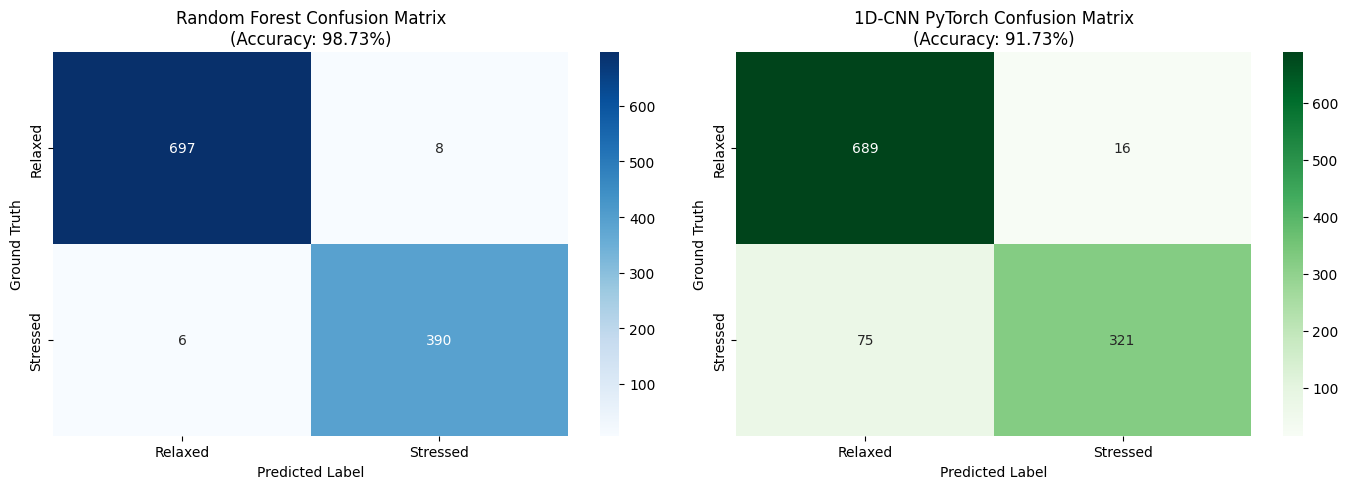


Confusion matrices saved to: /content/Output_ScreenShots/ScrePhase3_Confusion_Matrices.png
Phase 3 Implementation and Execution Pipeline Finished!


In [8]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Initializing Phase 3 Pipeline on Device: {device}")

file_path = "/content/WESAD_ML_Ready_Features.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found at {file_path}. Mount Google Drive first.")

df = pd.read_csv(file_path)

X = df.drop(columns=['Subject', 'State'])
y = df['State'].map({'Relaxed': 0, 'Stressed': 1}).values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"Dataset Loaded Successfully from: {file_path}")
print(f"Total Windows: {len(df)} | Training Set: {len(X_train)} | Testing Set: {len(X_test)}")
print(f"Feature Dimensions: {X_train.shape[1]} statistical metrics")

print("\n" + "="*60)
print("TRAINING MODEL 1: RANDOM FOREST BASELINE (Scikit-Learn)")
print("="*60)

rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=4,
    random_state=SEED,
    n_jobs=-1
)
rf_clf.fit(X_train, y_train)

y_pred_rf = rf_clf.predict(X_test)
rf_acc = accuracy_score(y_test, y_pred_rf)

print(f"\nRandom Forest Accuracy: {rf_acc * 100:.2f}%\n")
print("Random Forest Detailed Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Relaxed (0)', 'Stressed (1)']))

print("\n" + "="*60)
print("TRAINING MODEL 2: 1D-CNN ARCHITECTURE (PyTorch)")
print("="*60)

X_train_tensor = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class StressCNN1D(nn.Module):
    def __init__(self, in_channels=1, num_classes=2):
        super(StressCNN1D, self).__init__()

        self.conv1 = nn.Conv1d(in_channels=in_channels, out_channels=16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(16)
        self.relu1 = nn.ReLU()

        self.conv2 = nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm1d(32)
        self.relu2 = nn.ReLU()

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.2)
        self.fc = nn.Linear(32, num_classes)

    def forward(self, x):
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.relu2(self.bn2(self.conv2(x)))
        x = self.pool(x)
        x = x.squeeze(-1)
        x = self.dropout(x)
        logits = self.fc(x)
        return logits

cnn_model = StressCNN1D().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001, weight_decay=1e-4)

EPOCHS = 20
train_losses, val_losses = [], []

for epoch in range(1, EPOCHS + 1):
    cnn_model.train()
    running_train_loss = 0.0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = cnn_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    cnn_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = cnn_model(batch_X)
            loss = criterion(outputs, batch_y)
            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(test_loader.dataset)
    val_losses.append(epoch_val_loss)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

cnn_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        outputs = cnn_model(batch_X)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(batch_y.numpy())

cnn_acc = accuracy_score(all_targets, all_preds)

print("\n" + "="*60)
print("PHASE 3 COMPARATIVE MODEL SUMMARY")
print("="*60)
print(f"1. Random Forest Accuracy (Scikit-Learn) : {rf_acc * 100:.2f}%")
print(f"2. 1D-CNN Accuracy (PyTorch Framework)   : {cnn_acc * 100:.2f}%\n")

print("1D-CNN Detailed Classification Report:")
print(classification_report(all_targets, all_preds, target_names=['Relaxed (0)', 'Stressed (1)']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Relaxed', 'Stressed'], yticklabels=['Relaxed', 'Stressed'])
axes[0].set_title(f'Random Forest Confusion Matrix\n(Accuracy: {rf_acc*100:.2f}%)', fontsize=12)
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Ground Truth')

cm_cnn = confusion_matrix(all_targets, all_preds)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Relaxed', 'Stressed'], yticklabels=['Relaxed', 'Stressed'])
axes[1].set_title(f'1D-CNN PyTorch Confusion Matrix\n(Accuracy: {cnn_acc*100:.2f}%)', fontsize=12)
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Ground Truth')

plt.tight_layout()
output_plot_path = '/content/Output_ScreenShots/ScrePhase3_Confusion_Matrices.png'
plt.savefig(output_plot_path, dpi=300)
plt.show()

print(f"\nConfusion matrices saved to: {output_plot_path}")
print("Phase 3 Implementation and Execution Pipeline Finished!")